**Question 3.1 – Generate a DataFrame of research articles**

In [ ]:
import pandas as pd
import os
import glob

# Folder containing the research articles
folder_path = "research_corpus"

# Create an empty list
articles = []

# Find all text files in the folder
file_paths = glob.glob(os.path.join(folder_path, "*.txt"))

# Read each research article
for filepath in file_paths:

    with open(filepath, "r", encoding="utf-8") as file:

        content = file.read()

        articles.append({
            "Article": os.path.basename(filepath),
            "Content": content
        })

# Create the DataFrame
research_df = pd.DataFrame(articles)

# Display results
print("Total number of articles:", len(research_df))
display(research_df)


Total number of articles: 5


,Article,Content
0,research_1.txt,The purposes of this article are to position m...
1,research_2.txt,"Now I see it, now I don’t:\nresearcher’s posit..."
2,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...
3,research_4.txt,Abstract\nCronbach’s alpha is a statistic comm...
4,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulat...


In [4]:
print("DataFrame shape:", research_df.shape)
print("\nArticle names:")
print(research_df["Article"].tolist())

print("\nFirst article content:")
print(research_df["Content"].iloc[0])

DataFrame shape: (5, 2)

Article names:
['research_1.txt', 'research_2.txt', 'research_3.txt', 'research_4.txt', 'research_5.txt']

First article content:
The purposes of this article are to position mixed methods research
(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism
as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting
mixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative research, we explain the
tenets of pragmatism, we explain the fundamental principle of mixed
research and how to apply it, we provide specific sets of designs for
the two major types of mixed methods research (mixed-model designs and mixed-method designs), and, finally, we explain mixed methods research as following (recursively) an eight-ste

The five research articles were loaded from the local folder using Python. Their filenames and full textual content were stored in a Pandas DataFrame for further analysis.

**Question 3.2 – Preprocess research article content**

In [6]:
import nltk

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\mojap\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\mojap\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\mojap\AppData\Roaming\nltk_data...


True

In [7]:
import re
import html
import unicodedata
import nltk

from bs4 import BeautifulSoup
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Initialise preprocessing tools
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# Function to clean and preprocess text
def preprocess_text(text):

    # Remove HTML tags
    text = BeautifulSoup(text, "html.parser").get_text()

    # Decode HTML characters
    text = html.unescape(text)

    # Remove URLs and email addresses
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'\S+@\S+', '', text)

    # Convert to lowercase
    text = text.lower()

    # Normalize Unicode characters
    text = unicodedata.normalize('NFKC', text)

    # Remove numbers, punctuation and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    # Tokenization
    tokens = text.split()

    # Remove stop words and short tokens
    tokens = [
        word for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    # Lemmatization
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # Join tokens back into text
    return ' '.join(tokens)


# Apply preprocessing to all articles
research_df['Clean_Content'] = research_df['Content'].apply(preprocess_text)

# Display the results
display(research_df[['Article', 'Clean_Content']])


,Article,Clean_Content
0,research_1.txt,purpose article position mixed method research...
1,research_2.txt,see researcher position reflexivity qualitativ...
2,research_3.txt,developmental research study instructional des...
3,research_4.txt,abstract cronbach alpha statistic commonly quo...
4,research_5.txt,denzin paradigm shift revisiting triangulation...


In [8]:
# Display the first article before preprocessing
print("ORIGINAL ARTICLE:")
print(research_df['Content'].iloc[0][:1000])

# Display the first article after preprocessing
print("\nCLEANED ARTICLE:")
print(research_df['Clean_Content'].iloc[0][:1000])

ORIGINAL ARTICLE:
The purposes of this article are to position mixed methods research
(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism
as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting
mixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative research, we explain the
tenets of pragmatism, we explain the fundamental principle of mixed
research and how to apply it, we provide specific sets of designs for
the two major types of mixed methods research (mixed-model designs and mixed-method designs), and, finally, we explain mixed methods research as following (recursively) an eight-step process. A key
feature of mixed methods research is its methodological pluralism
or eclecticism, which frequently results in superior r

In [9]:
print("Total articles:", len(research_df))

print("\nMissing cleaned content:")
print(research_df['Clean_Content'].isnull().sum())

print("\nCleaned content lengths:")
print(research_df['Clean_Content'].str.len())

Total articles: 5

Missing cleaned content:
0

Cleaned content lengths:
0    26855
1    10859
2    18702
3    26620
4    18969
Name: Clean_Content, dtype: int64


The research articles were preprocessed using NLP techniques. HTML tags, URLs, punctuation and special characters were removed. The text was converted to lowercase, tokenised, filtered using English stop words and lemmatised to reduce words to their base forms. This produced cleaner text for summarisation and topic modelling.

**Question 3.3 – Summarise the first research article**

In [10]:
import re
from collections import Counter
import matplotlib.pyplot as plt

# Get the first research article
first_article = research_df['Content'].iloc[0]
cleaned_article = research_df['Clean_Content'].iloc[0]

# Split the original article into sentences
sentences = re.split(r'(?<=[.!?])\s+', first_article.strip())

# Calculate word frequencies from the cleaned article
word_frequencies = Counter(cleaned_article.split())

# Score each sentence according to its word frequencies
sentence_scores = []

for sentence in sentences:
    cleaned_sentence = preprocess_text(sentence)
    words = cleaned_sentence.split()

    if words:
        score = sum(word_frequencies[word] for word in words) / len(words)
        sentence_scores.append((score, sentence))

# Select the three highest-scoring sentences
top_sentences = sorted(sentence_scores, reverse=True)[:3]

# Keep the selected sentences in their original order
top_sentences = sorted(
    top_sentences,
    key=lambda x: sentences.index(x[1])
)

summary = " ".join(sentence for score, sentence in top_sentences)

print("FIRST ARTICLE SUMMARY:")
print(summary)

FIRST ARTICLE SUMMARY:
Our purpose in writing this article is to present mixed methods research as the third research paradigm in educational research.5 We hope the field will move beyond quantitative versus
qualitative research arguments because, as recognized by mixed
methods research, both quantitative and qualitative research are
important and useful. Mixed methods research as the third research
paradigm can also help bridge the schism between quantitative
and qualitative research (Onwuegbuzie & Leech, 2004a). Mixed methods research as the third research
paradigm can also help bridge the schism between quantitative
and qualitative research (Onwuegbuzie & Leech, 2004a).


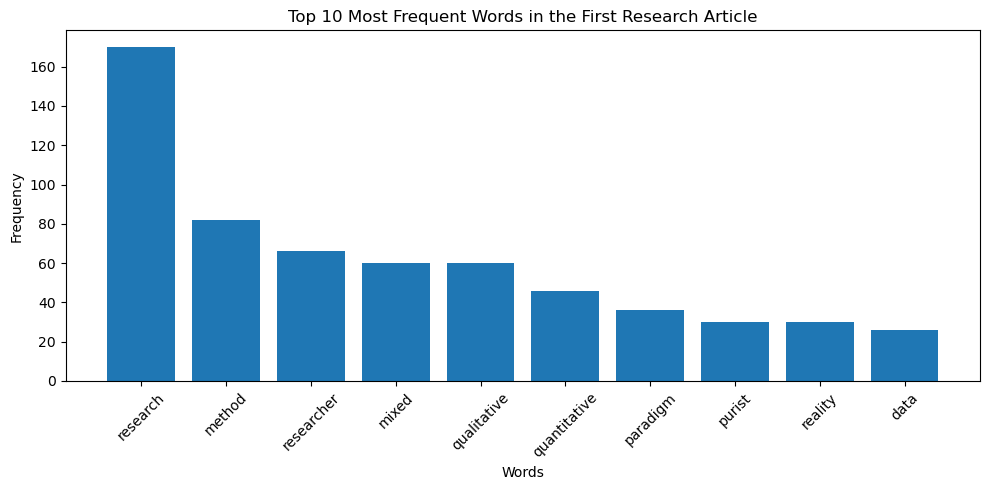

In [11]:
# Get the 10 most frequent words
top_words = word_frequencies.most_common(10)

words = [word for word, frequency in top_words]
frequencies = [frequency for word, frequency in top_words]

# Create bar chart
plt.figure(figsize=(10, 5))
plt.bar(words, frequencies)

plt.title("Top 10 Most Frequent Words in the First Research Article")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
original_words = len(first_article.split())
summary_words = len(summary.split())

print("Original word count:", original_words)
print("Summary word count:", summary_words)

reduction = ((original_words - summary_words) / original_words) * 100

print("Reduction in word count:", round(reduction, 2), "%")

Original word count: 5602
Summary word count: 94
Reduction in word count: 98.32 %


The first research article was summarised using frequency-based extractive summarisation. The technique scored sentences according to the frequency of their meaningful words and selected the three highest-scoring sentences. A bar chart was created to display the ten most frequent words in the article.

**Question 3.4 – Summarise the remaining research articles**

In [15]:
import pandas as pd
import re
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer

print('imports completed successfully')

# Select articles 2 to 5
remaining_articles = research_df.iloc[1:].copy()

print("Number of remaining articles:", len(remaining_articles))
display(remaining_articles[['Article', 'Clean_Content']])

imports completed successfully
Number of remaining articles: 4


,Article,Clean_Content
1,research_2.txt,see researcher position reflexivity qualitativ...
2,research_3.txt,developmental research study instructional des...
3,research_4.txt,abstract cronbach alpha statistic commonly quo...
4,research_5.txt,denzin paradigm shift revisiting triangulation...


In [16]:
def tfidf_summary(article, number_of_sentences=3):

    # Split article into sentences
    sentences = re.split(r'(?<=[.!?])\s+', article.strip())
    sentences = [s for s in sentences if s.strip()]

    if len(sentences) <= number_of_sentences:
        return article

    # Clean each sentence
    cleaned_sentences = [preprocess_text(s) for s in sentences]

    # Calculate TF-IDF scores
    vectorizer = TfidfVectorizer(stop_words='english')
    tfidf_matrix = vectorizer.fit_transform(cleaned_sentences)

    # Calculate average TF-IDF score per sentence
    scores = tfidf_matrix.mean(axis=1).A1

    # Select the highest-scoring sentences
    top_indices = scores.argsort()[-number_of_sentences:]

    # Keep sentences in their original order
    top_indices = sorted(top_indices)

    return " ".join(sentences[i] for i in top_indices)


# Generate summaries for all remaining articles
remaining_articles['Summary'] = remaining_articles['Content'].apply(tfidf_summary)

# Display the summaries
for index, row in remaining_articles.iterrows():
    print("\nARTICLE:", row['Article'])
    print("SUMMARY:")
    print(row['Summary'])
    print("-" * 80)


ARTICLE: research_2.txt
SUMMARY:
Reflexivity has been increasingly recognized as a crucial strategy in the process of generating knowledge by means of qualitative research
(Ahmed Dunya et al., 2011; Blaxter et al., 2006; D’Cruz et al., 2007; Gerstl-Pepin
and Patrizion, 2009; Hammersley and Atkinson, 2002; Horsburgh, 2003; Koch and
Harrington, 1998).For example, the journal Forum: Qualitative Research dedicated a
full issue (May 2003) to subjectivity and reflexivity in qualitative research, and there
Corresponding author:
Roni Berger, School of Social Work, Adelphi University, 1 South Avenue, Garden City, NY 11530, USA. Strategies for maintaining reflexivity include
repeated interviews with the same participants, prolonged engagement, members checking, triangulation, peer review, forming of a peer support network and back talk groups,
keeping a diary or research journal for ‘self-supervision’, and creating an ‘audit trail’ of
researcher’s reasoning, judgment, and emotional reactions (A

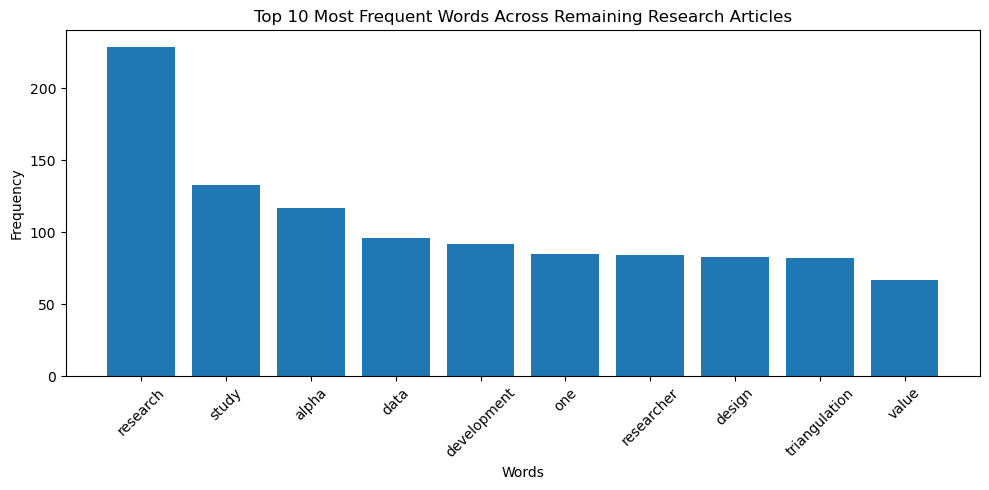

In [17]:
from collections import Counter

# Combine the cleaned content
combined_text = " ".join(remaining_articles['Clean_Content'])

# Count word frequencies
word_frequencies = Counter(combined_text.split())

# Get the 10 most frequent words
top_words = word_frequencies.most_common(10)

words = [word for word, frequency in top_words]
frequencies = [frequency for word, frequency in top_words]

# Create bar chart
plt.figure(figsize=(10, 5))
plt.bar(words, frequencies)

plt.title("Top 10 Most Frequent Words Across Remaining Research Articles")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

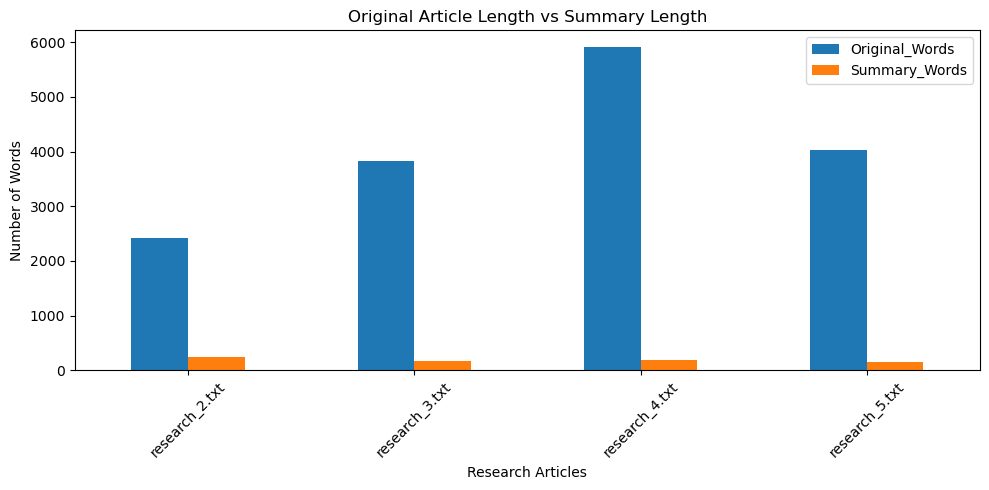

In [18]:
remaining_articles['Original_Words'] = remaining_articles['Content'].apply(
    lambda x: len(x.split())
)

remaining_articles['Summary_Words'] = remaining_articles['Summary'].apply(
    lambda x: len(x.split())
)

# Plot comparison
remaining_articles.set_index('Article')[
    ['Original_Words', 'Summary_Words']
].plot(kind='bar', figsize=(10, 5))

plt.title("Original Article Length vs Summary Length")
plt.xlabel("Research Articles")
plt.ylabel("Number of Words")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The remaining four research articles were summarised using TF-IDF-based extractive summarisation. TF-IDF was used to identify sentences containing important terms, and the three highest-scoring sentences from each article were selected. Bar charts were generated to display the most frequent words across the articles and compare the original article lengths with their summaries.

**Question 4.1 – Use LDA to identify the top research topics**

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
print('imports successfully')

documents = research_df['Clean_Content'].fillna('').tolist()

print('Number of documents:', len(documents))

imports successfully
Number of documents: 5


In [21]:
vectorizer = CountVectorizer(
    stop_words='english',
    max_features=1000,
    min_df=1,
    max_df=1.0
)

doc_term_matrix = vectorizer.fit_transform(documents)

print("Document-term matrix shape:", doc_term_matrix.shape)

Document-term matrix shape: (5, 1000)


In [22]:
lda_model = LatentDirichletAllocation(
    n_components=3,
    random_state=42,
    learning_method='batch',
    max_iter=20
)

lda_model.fit(doc_term_matrix)

print("LDA model trained successfully.")

LDA model trained successfully.


In [23]:
feature_names = vectorizer.get_feature_names_out()

n_top_words = 10

topic_words = {}

for topic_index, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-n_top_words:][::-1]

    words = [feature_names[i] for i in top_indices]

    topic_words[f"Topic {topic_index + 1}"] = words

    print(f"\nTopic {topic_index + 1}:")
    print(", ".join(words))


Topic 1:
data, triangulation, researcher, research, study, method, qualitative, design, reflexivity, denzin

Topic 2:
research, method, development, researcher, qualitative, mixed, design, process, quantitative, developmental

Topic 3:
alpha, cronbach, instrument, value, reliability, science, scale, study, item, education


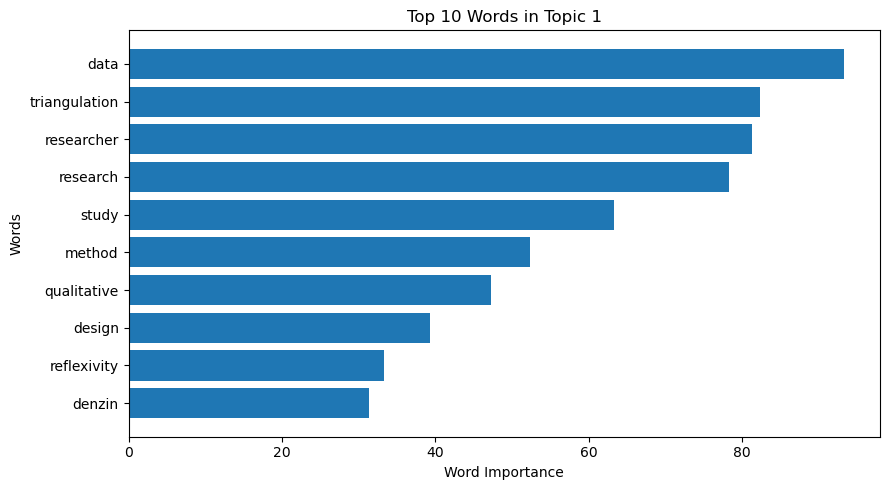

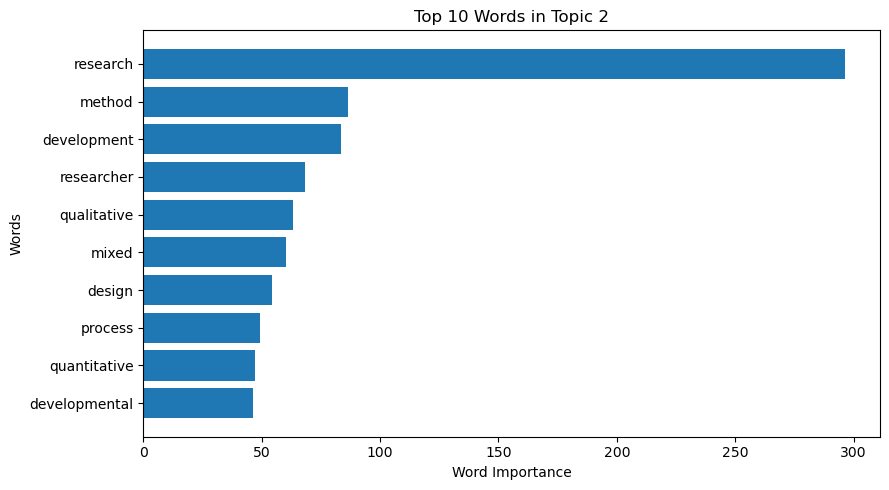

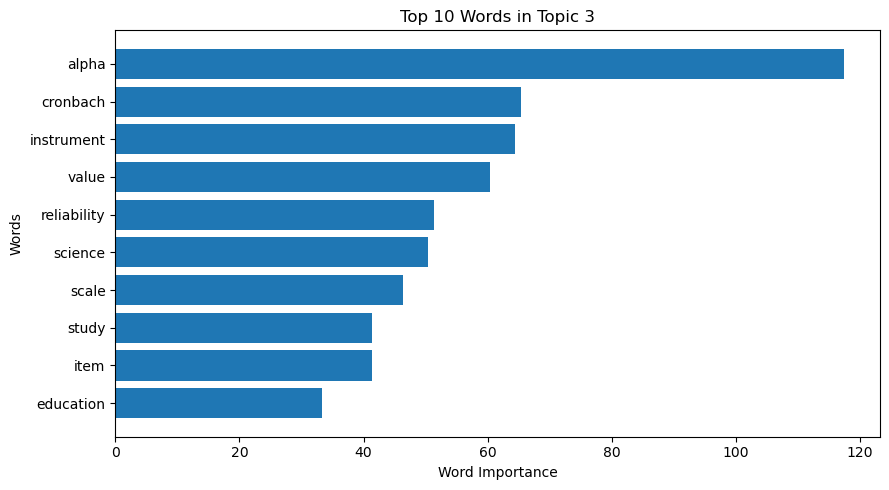

In [26]:
for topic_index, topic in enumerate(lda_model.components_):

    top_indices = topic.argsort()[-10:][::-1]

    words = [feature_names[i] for i in top_indices]
    weights = [topic[i] for i in top_indices]

    plt.figure(figsize=(9, 5))
    plt.barh(words[::-1], weights[::-1])

    plt.title(f"Top 10 Words in Topic {topic_index + 1}")
    plt.xlabel("Word Importance")
    plt.ylabel("Words")
    plt.tight_layout()
    plt.show()